# Практична робота №3 Дослідження ефективності TF-IDF зважених ембеддингів для детекції AI-текстів


In [ ]:
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import spacy
from gensim.models import FastText
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    f1_score, accuracy_score, balanced_accuracy_score, roc_auc_score,
    confusion_matrix, classification_report
)
from sklearn.manifold import TSNE
from sklearn.preprocessing import LabelEncoder
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
SEED = 42
DATA_DIR = Path("data")
OUT = Path("results_ml_practice_3")
OUT.mkdir(exist_ok=True)

## Завантаження датасету

In [8]:
data_file = 'ai_vs_human_text_2026.csv'

df_raw = pd.read_csv(data_file)

print("Файл:", data_file)
print("Розмір таблиці:", df_raw.shape)
print("Колонки:", list(df_raw.columns))

display(df_raw.head())

Файл: ai_vs_human_text_2026.csv
Розмір таблиці: (2000, 9)
Колонки: ['text_id', 'label', 'source_model', 'domain', 'text_content', 'topic_hint', 'word_count', 'avg_sentence_length', 'generation_method']


,text_id,label,source_model,domain,text_content,topic_hint,word_count,avg_sentence_length,generation_method
0,TXT_0001,human,human,social,can we talk about gene editing ethics for a se...,gene editing ethics,27,13.5,template+human_variation
1,TXT_0002,human,human,social,update on election integrity concerns: it's co...,election integrity concerns,20,10.0,template+human_variation
2,TXT_0003,ai,gemini-2.0,news,Analysts are closely watching developments rel...,climate change adaptation strategies,39,13.0,style_simulation
3,TXT_0004,human,human,academic,This paper examines genomic research breakthro...,genomic research breakthroughs,49,16.3,template+human_variation
4,TXT_0005,ai,gpt-4o,academic,Existing literature on student debt crisis has...,student debt crisis,42,10.8,style_simulation


## Визначення колонок та очищення даних

In [9]:
# Якщо автоматично вибрано не ті колонки, задати їх вручну
TEXT_COL = None
LABEL_COL = None

def detect_column(df, requested, candidates, kind):
    if requested:
        if requested not in df.columns:
            raise ValueError(f"Колонка {requested!r} відсутня. Є: {list(df.columns)}")
        return requested
    lower = {str(c).strip().lower(): c for c in df.columns}
    for c in candidates:
        if c in lower:
            return lower[c]
    if kind == "text":
        possible = [
            c for c in df.columns
            if df[c].dtype == "object" and df[c].astype(str).str.len().median() > 30
        ]
        if possible:
            return max(possible, key=lambda c: df[c].astype(str).str.len().median())
    else:
        possible = [
            c for c in df.columns
            if 2 <= df[c].nunique(dropna=True) <= 20 and str(c).lower() not in ("id", "index")
        ]
        if possible:
            return possible[-1]
    raise ValueError(f"Не вдалося визначити колонку {kind}. Наявні колонки: {list(df.columns)}")

text_col = detect_column(
    df_raw, TEXT_COL,
    ["text", "content", "essay", "document", "article", "sentence", "text_content"],
    "text"
)
label_col = detect_column(
    df_raw, LABEL_COL,
    ["label", "generated", "source", "class", "author", "is_ai", "ai_generated", "type"],
    "label"
)
print("Колонка тексту:", text_col)
print("Колонка класу:", label_col)

df = df_raw[[text_col, label_col]].copy()
n_initial = len(df)
missing_text = int(df[text_col].isna().sum())
missing_label = int(df[label_col].isna().sum())
duplicate_texts = int(df[text_col].astype(str).duplicated().sum())

df[text_col] = df[text_col].fillna("").astype(str).str.strip()
df = df[(df[text_col] != "") & df[label_col].notna()].copy()
df = df.drop_duplicates(subset=[text_col]).reset_index(drop=True)

# Для швидкого пробного запуску можна задати, наприклад, MAX_ROWS = 3000.
# 0 означає використати весь датасет.
MAX_ROWS = 0
if MAX_ROWS and len(df) > MAX_ROWS:
    df, _ = train_test_split(
        df, train_size=MAX_ROWS, random_state=SEED,
        stratify=df[label_col].astype(str)
    )
    df = df.reset_index(drop=True)

print(f"Початкових рядків: {n_initial}")
print(f"Пропущених текстів: {missing_text}; пропущених міток: {missing_label}")
print(f"Дублікатів тексту до видалення: {duplicate_texts}")
print(f"Рядків після очищення: {len(df)}")
display(df.head())

Колонка тексту: text_content
Колонка класу: label
Початкових рядків: 2000
Пропущених текстів: 0; пропущених міток: 0
Дублікатів тексту до видалення: 1034
Рядків після очищення: 966


,text_content,label
0,can we talk about gene editing ethics for a se...,human
1,update on election integrity concerns: it's co...,human
2,Analysts are closely watching developments rel...,ai
3,This paper examines genomic research breakthro...,human
4,Existing literature on student debt crisis has...,ai


## Баланс класів і довжина текстів

,Кількість текстів
Human,579
AI,387


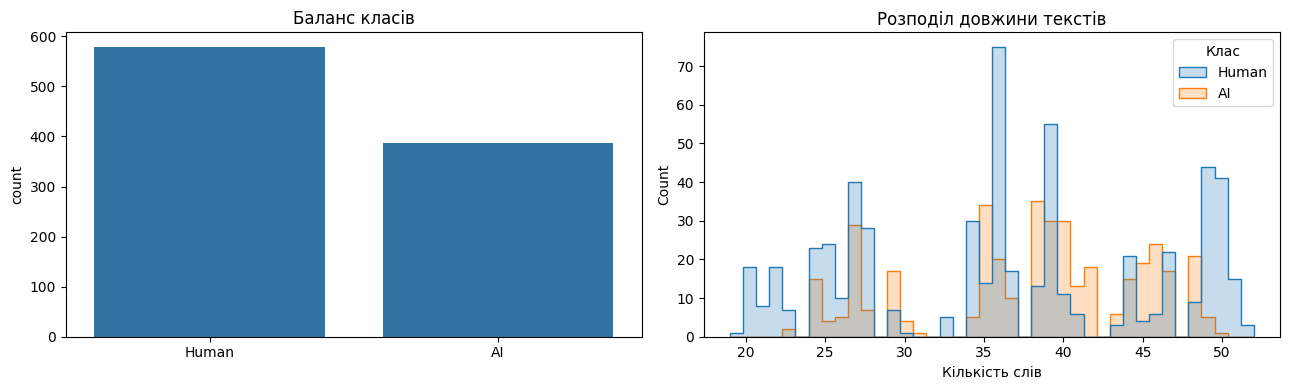

In [10]:
def normalize_labels(series):
    s = series.copy()
    numeric = pd.to_numeric(s, errors="coerce")
    if numeric.notna().all() and set(numeric.unique()).issubset({0, 1}):
        return numeric.astype(int).to_numpy(), {0: "Human", 1: "AI"}
    vals = s.astype(str).str.strip().str.lower()
    mapping = {}
    for v in vals.unique():
        if v in {"0", "human", "human-written", "human written", "real", "person"} or "human" in v:
            mapping[v] = 0
        elif v in {"1", "ai", "generated", "ai-generated", "ai generated", "machine"} or "ai" in v or "generat" in v or "chatgpt" in v:
            mapping[v] = 1
    if len(mapping) == vals.nunique() and set(mapping.values()) == {0, 1}:
        return vals.map(mapping).astype(int).to_numpy(), {0: "Human", 1: "AI"}
    le = LabelEncoder()
    enc = le.fit_transform(s.astype(str))
    if len(le.classes_) != 2:
        raise ValueError(f"Очікується рівно два класи, знайдено: {list(le.classes_)}")
    print("Увага: автоматичне кодування класів:", dict(enumerate(le.classes_)))
    return enc, {int(i): str(v) for i, v in enumerate(le.classes_)}

y, label_names = normalize_labels(df[label_col])
if len(np.unique(y)) != 2:
    raise ValueError("Датасет повинен містити рівно два класи.")

df["word_count"] = df[text_col].astype(str).str.split().str.len()
class_counts = pd.Series([label_names[int(v)] for v in y]).value_counts()
display(class_counts.rename("Кількість текстів").to_frame())

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.countplot(x=[label_names[int(v)] for v in y], ax=axes[0])
axes[0].set_title("Баланс класів")
sns.histplot(
    data=pd.DataFrame({"Клас": [label_names[int(v)] for v in y],
                       "Кількість слів": df["word_count"]}),
    x="Кількість слів", hue="Клас", bins=40, element="step",
    stat="count", common_norm=False, ax=axes[1]
)
axes[1].set_title("Розподіл довжини текстів")
plt.tight_layout()
plt.show()

## Попередня обробка текстів за допомогою spaCy

In [13]:
try:
    nlp = spacy.load("en_core_web_sm", disable=["ner", "parser"])
except OSError as e:
    raise RuntimeError(
        "Не знайдено модель en_core_web_sm. Виконай у новій комірці: "
        "%pip install spacy && !python -m spacy download en_core_web_sm"
    ) from e

def preprocess_corpus(texts, nlp, batch_size=128):
    processed = []
    for doc in nlp.pipe((str(t) for t in texts), batch_size=batch_size):
        tokens = [
            tok.lemma_.lower() for tok in doc
            if tok.is_alpha and not tok.is_stop and tok.lemma_.strip()
        ]
        processed.append(tokens)
    return processed

texts = df[text_col].tolist()
tokens = preprocess_corpus(texts, nlp)
keep = np.array([len(t) > 0 for t in tokens])
df = df.loc[keep].reset_index(drop=True)
tokens = [t for t, k in zip(tokens, keep) if k]
y = y[keep]

print("Текстів після spaCy-обробки:", len(tokens))
print("Приклад оригінального тексту:")
print(df.loc[0, text_col][:500])
print("\nПриклад токенів:")
print(tokens[0][:40])

Текстів після spaCy-обробки: 966
Приклад оригінального тексту:
can we talk about gene editing ethics for a sec because i feel like people are completely missing the point here. this is bigger than most realize

Приклад токенів:
['talk', 'gene', 'edit', 'ethic', 'sec', 'feel', 'like', 'people', 'completely', 'miss', 'point', 'big', 'realize']


## Поділ вибірки та навчання FastText

In [15]:
import numpy as np
from sklearn.model_selection import train_test_split
from gensim.models import FastText

# 1. Розділення даних на навчальну та тестову вибірки
indices = np.arange(len(y))

train_idx, test_idx = train_test_split(
    indices,
    test_size=0.2,
    random_state=SEED,
    stratify=y
)

y_train, y_test = y[train_idx], y[test_idx]

print(f"Навчальна вибірка: {len(train_idx)}")
print(f"Тестова вибірка: {len(test_idx)}")

# 2. Формування навчального корпусу текстів
corpus_train = [tokens[i] for i in train_idx]

# 3. Навчання моделі FastText
ft = FastText(
    sentences=corpus_train,
    vector_size=100,
    window=5,
    min_count=2,
    sg=1,
    workers=4,
    seed=SEED,
    epochs=10
)

# 4. Збереження моделі
OUT.mkdir(parents=True, exist_ok=True)
ft.save(str(OUT / "fasttext.model"))

print("FastText успішно навчено.")
print("Розмірність вектора:", ft.vector_size)
print("Кількість слів у словнику:", len(ft.wv))

Навчальна вибірка: 772
Тестова вибірка: 194
FastText успішно навчено.
Розмірність вектора: 100
Кількість слів у словнику: 508


## Mean Pooling та TF-IDF Weighted Mean

In [16]:
def mean_pooling(doc_tokens, model):
    vectors = [model.wv[t] for t in doc_tokens if t in model.wv]
    return np.mean(vectors, axis=0) if vectors else np.zeros(model.vector_size, dtype=np.float32)

def weighted_pooling(doc_tokens, model, tfidf_row, feature_index):
    vectors, weights = [], []
    for token in doc_tokens:
        idx = feature_index.get(token)
        if idx is not None and token in model.wv:
            weight = float(tfidf_row[0, idx])
            if weight > 0:
                vectors.append(model.wv[token])
                weights.append(weight)
    if not vectors or sum(weights) == 0:
        return np.zeros(model.vector_size, dtype=np.float32)
    return np.average(np.asarray(vectors), axis=0, weights=np.asarray(weights))

vectorizer = TfidfVectorizer(
    tokenizer=str.split, preprocessor=None, token_pattern=None,
    lowercase=False, min_df=2, max_features=50000
)
train_docs = [" ".join(tokens[i]) for i in train_idx]
all_docs = [" ".join(t) for t in tokens]
vectorizer.fit(train_docs)
tfidf_all = vectorizer.transform(all_docs)
feature_names = vectorizer.get_feature_names_out()
feature_index = {word: i for i, word in enumerate(feature_names)}

X_mean = np.vstack([mean_pooling(t, ft) for t in tokens])
X_tfidf = np.vstack([
    weighted_pooling(tokens[i], ft, tfidf_all[i], feature_index)
    for i in range(len(tokens))
])

np.save(OUT / "X_mean.npy", X_mean)
np.save(OUT / "X_tfidf.npy", X_tfidf)
print("Mean Pooling:", X_mean.shape)
print("TF-IDF Weighted Mean:", X_tfidf.shape)

Mean Pooling: (966, 100)
TF-IDF Weighted Mean: (966, 100)


## Навчання класифікаторів та оцінювання


Метод агрегації: Mean Pooling


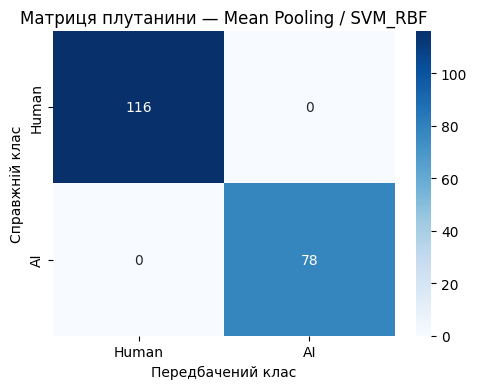

              precision    recall  f1-score   support

       Human       1.00      1.00      1.00       116
          AI       1.00      1.00      1.00        78

    accuracy                           1.00       194
   macro avg       1.00      1.00      1.00       194
weighted avg       1.00      1.00      1.00       194



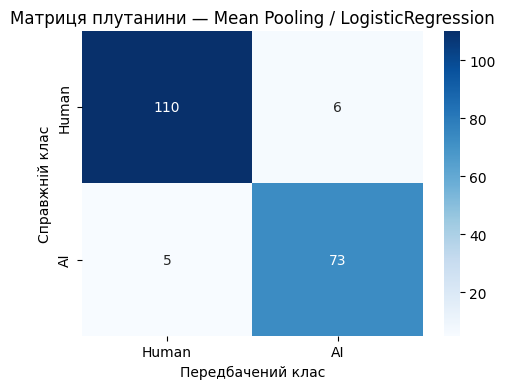

              precision    recall  f1-score   support

       Human       0.96      0.95      0.95       116
          AI       0.92      0.94      0.93        78

    accuracy                           0.94       194
   macro avg       0.94      0.94      0.94       194
weighted avg       0.94      0.94      0.94       194



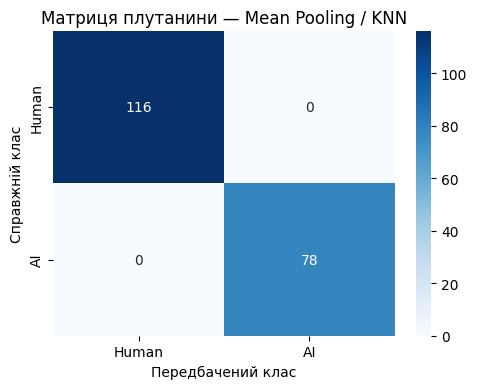

              precision    recall  f1-score   support

       Human       1.00      1.00      1.00       116
          AI       1.00      1.00      1.00        78

    accuracy                           1.00       194
   macro avg       1.00      1.00      1.00       194
weighted avg       1.00      1.00      1.00       194


Метод агрегації: TF-IDF Weighted Mean


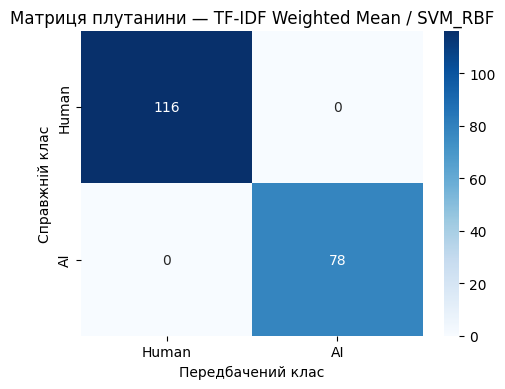

              precision    recall  f1-score   support

       Human       1.00      1.00      1.00       116
          AI       1.00      1.00      1.00        78

    accuracy                           1.00       194
   macro avg       1.00      1.00      1.00       194
weighted avg       1.00      1.00      1.00       194



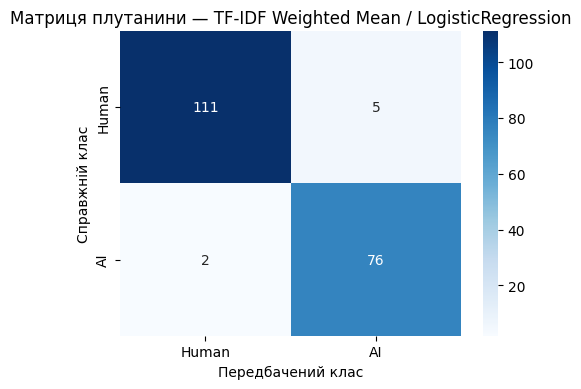

              precision    recall  f1-score   support

       Human       0.98      0.96      0.97       116
          AI       0.94      0.97      0.96        78

    accuracy                           0.96       194
   macro avg       0.96      0.97      0.96       194
weighted avg       0.96      0.96      0.96       194



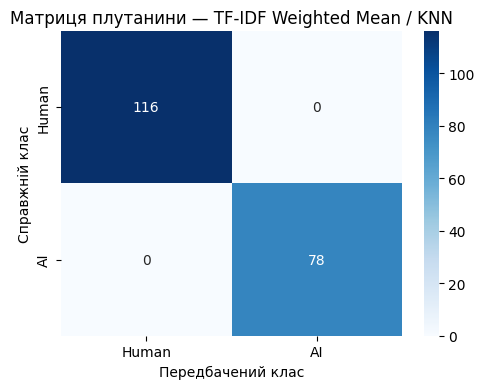

              precision    recall  f1-score   support

       Human       1.00      1.00      1.00       116
          AI       1.00      1.00      1.00        78

    accuracy                           1.00       194
   macro avg       1.00      1.00      1.00       194
weighted avg       1.00      1.00      1.00       194



,Aggregation,Classifier,F1_macro,Accuracy,Balanced_Accuracy,ROC_AUC
0,Mean Pooling,SVM_RBF,1.000000,1.000000,1.000000,1.000000
1,Mean Pooling,KNN,1.000000,1.000000,1.000000,1.000000
2,TF-IDF Weighted Mean,SVM_RBF,1.000000,1.000000,1.000000,1.000000
3,TF-IDF Weighted Mean,KNN,1.000000,1.000000,1.000000,1.000000
4,TF-IDF Weighted Mean,LogisticRegression,0.962704,0.963918,0.965628,0.993369
5,Mean Pooling,LogisticRegression,0.941159,0.943299,0.942087,0.991490


Найкраща комбінація за Macro F1:


,Aggregation,Classifier,F1_macro,Accuracy,Balanced_Accuracy,ROC_AUC
0,Mean Pooling,SVM_RBF,1.0,1.0,1.0,1.0


In [17]:
classifiers = {
    "SVM_RBF": SVC(kernel="rbf", probability=True, random_state=SEED),
    "LogisticRegression": LogisticRegression(max_iter=1000, random_state=SEED),
    "KNN": KNeighborsClassifier(n_neighbors=5)
}

records = []
fitted = {}
for method, X in [("Mean Pooling", X_mean), ("TF-IDF Weighted Mean", X_tfidf)]:
    print("\nМетод агрегації:", method)
    for clf_name, clf_template in classifiers.items():
        # Створюємо окремий екземпляр класифікатора для кожного експерименту.
        from sklearn.base import clone
        clf = clone(clf_template)
        clf.fit(X[train_idx], y_train)
        pred = clf.predict(X[test_idx])
        try:
            prob = clf.predict_proba(X[test_idx])[:, 1]
            auc = roc_auc_score(y_test, prob)
        except Exception:
            auc = float("nan")
        rec = {
            "Aggregation": method,
            "Classifier": clf_name,
            "F1_macro": f1_score(y_test, pred, average="macro", zero_division=0),
            "Accuracy": accuracy_score(y_test, pred),
            "Balanced_Accuracy": balanced_accuracy_score(y_test, pred),
            "ROC_AUC": auc
        }
        records.append(rec)
        fitted[(method, clf_name)] = clf

        cm = confusion_matrix(y_test, pred, labels=[0, 1])
        plt.figure(figsize=(5, 4))
        sns.heatmap(
            cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=[label_names[0], label_names[1]],
            yticklabels=[label_names[0], label_names[1]]
        )
        plt.xlabel("Передбачений клас")
        plt.ylabel("Справжній клас")
        plt.title(f"Матриця плутанини — {method} / {clf_name}")
        plt.tight_layout()
        safe_method = method.lower().replace(" ", "_").replace("-", "_")
        plt.savefig(OUT / f"confusion_{safe_method}_{clf_name}.png", dpi=160)
        plt.show()

        report = classification_report(
            y_test, pred, target_names=[label_names[0], label_names[1]],
            zero_division=0
        )
        (OUT / f"report_{safe_method}_{clf_name}.txt").write_text(report, encoding="utf-8")
        print(report)

results = pd.DataFrame(records).sort_values(
    ["F1_macro", "Accuracy"], ascending=False
).reset_index(drop=True)
results.to_csv(OUT / "metrics.csv", index=False, encoding="utf-8-sig")
display(results)
print("Найкраща комбінація за Macro F1:")
display(results.iloc[[0]])

## Топ-терміни TF-IDF для класу AI


,term,mean_tfidf_ai
0,challenge,0.039944
1,think,0.035265
2,conversation,0.033382
3,framework,0.031881
4,point,0.030439
5,expert,0.030210
6,development,0.029551
7,research,0.028521
8,solution,0.028086
9,datum,0.027979


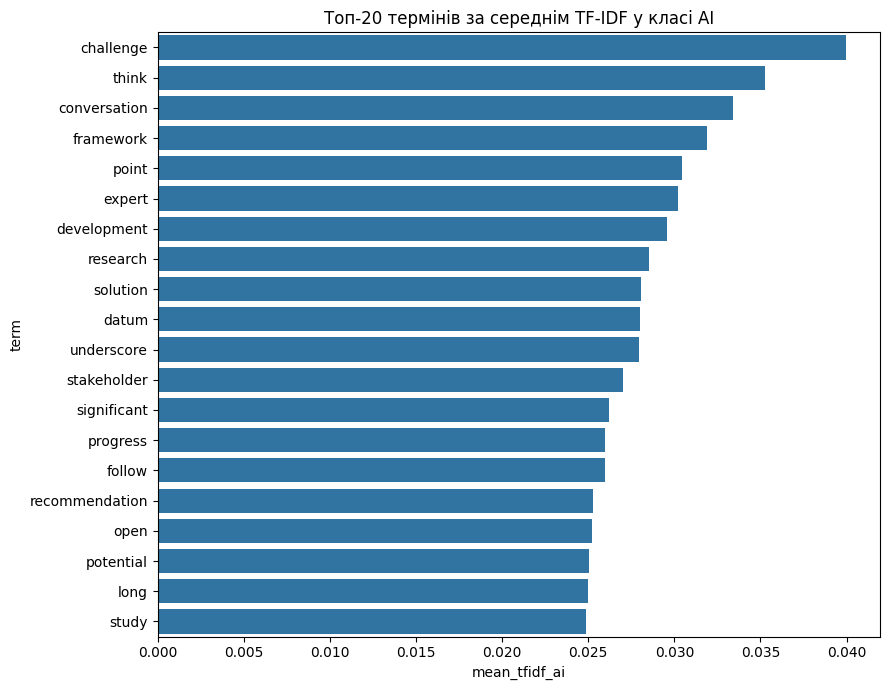

In [18]:
ai_rows = np.where(y == 1)[0]
mean_scores = np.asarray(tfidf_all[ai_rows].mean(axis=0)).ravel()
top_idx = np.argsort(mean_scores)[::-1][:30]
top_terms = pd.DataFrame({
    "term": feature_names[top_idx],
    "mean_tfidf_ai": mean_scores[top_idx]
})
top_terms.to_csv(OUT / "top_tfidf_terms_ai.csv", index=False, encoding="utf-8-sig")
display(top_terms)

plt.figure(figsize=(9, 7))
sns.barplot(data=top_terms.head(20), x="mean_tfidf_ai", y="term")
plt.title("Топ-20 термінів за середнім TF-IDF у класі AI")
plt.tight_layout()
plt.savefig(OUT / "top_tfidf_terms_ai.png", dpi=160)
plt.show()

## Візуалізація t-SNE

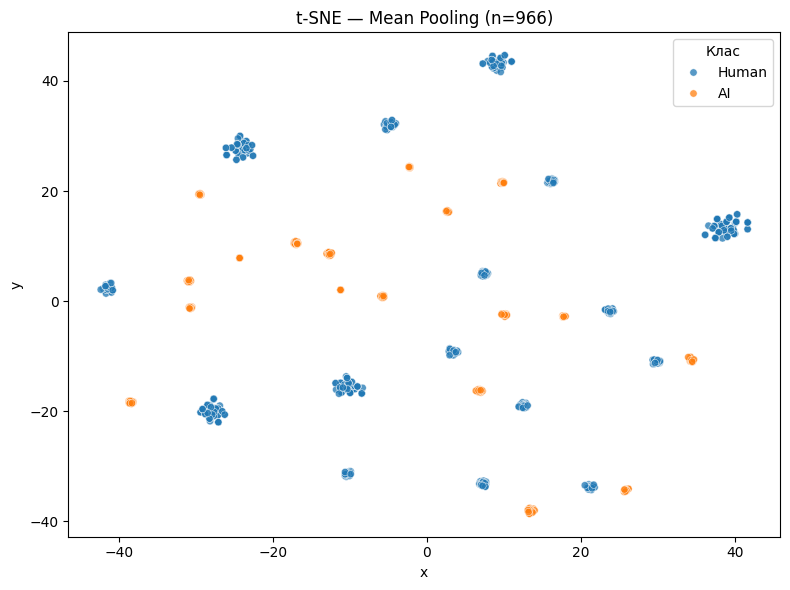

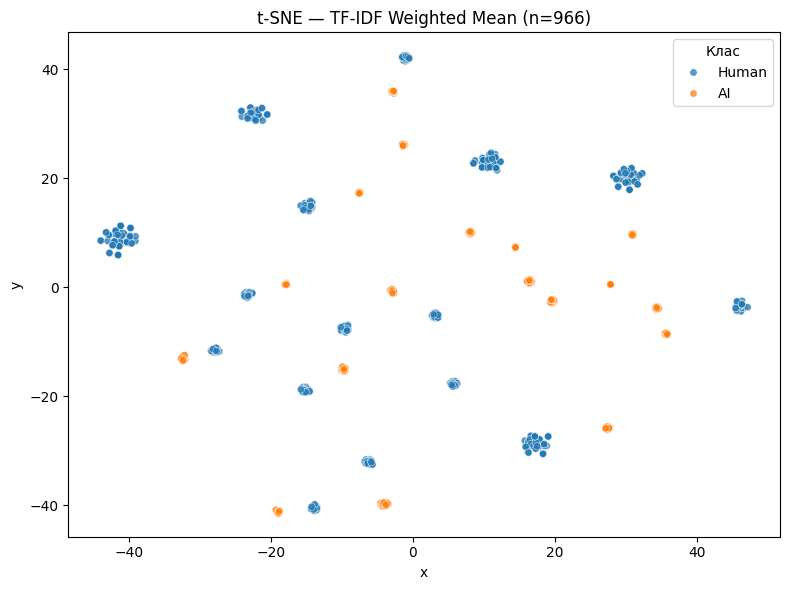

In [19]:
rng = np.random.default_rng(SEED)
TSNE_SAMPLES = 1500  # зменш це число, якщо обчислення тривають надто довго
if len(y) > TSNE_SAMPLES:
    tsne_idx = np.sort(rng.choice(len(y), size=TSNE_SAMPLES, replace=False))
else:
    tsne_idx = np.arange(len(y))

if len(tsne_idx) >= 4:
    perplexity = min(30, max(2, (len(tsne_idx) - 1) // 3))
    for method, X in [
        ("Mean Pooling", X_mean),
        ("TF-IDF Weighted Mean", X_tfidf)
    ]:
        emb = TSNE(
            n_components=2, random_state=SEED, perplexity=perplexity,
            init="pca", learning_rate="auto"
        ).fit_transform(X[tsne_idx])
        plot_df = pd.DataFrame({
            "x": emb[:, 0],
            "y": emb[:, 1],
            "Клас": [label_names[int(v)] for v in y[tsne_idx]]
        })
        plt.figure(figsize=(8, 6))
        sns.scatterplot(data=plot_df, x="x", y="y", hue="Клас", alpha=0.75, s=28)
        plt.title(f"t-SNE — {method} (n={len(tsne_idx)})")
        plt.tight_layout()
        safe_method = method.lower().replace(" ", "_").replace("-", "_")
        plt.savefig(OUT / f"tsne_{safe_method}.png", dpi=160)
        plt.show()
else:
    print("Недостатньо прикладів для t-SNE.")